# Perfis econômicos de Brasil, China e Estados Unidos (2004–2024)
## Opção B — Aprendizado não supervisionado: agrupamento

**Pergunta:** quais perfis de renda, produtividade, estrutura de emprego e distribuição da renda aparecem no painel, e como os países transitam entre eles?

A unidade de análise é **país-ano**: 63 observações, 3 países e 21 anos. Não há variável-alvo. País e ano são identificadores usados para interpretar os grupos; não entram no modelo. O estudo mantém o tema do projeto original e acrescenta modelagem não supervisionada.

**Como executar:** na raiz do repositório, instale `requirements.txt`, abra este notebook e execute todas as células em ordem. A fotografia reduzida das fontes já está em `data/raw/`; a execução é offline. O código completo, comentado, está em `src/prepare_data.py` e `src/analysis.py`.

In [1]:
from pathlib import Path
import sys, json, platform
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "prepare_data.py").exists():
    raise RuntimeError("Abra e execute o notebook a partir da raiz do repositório.")
sys.path.insert(0, str(ROOT / "src"))
from prepare_data import build_panel
from analysis import FeatureTransform, RAW_COLUMNS, FEATURE_NAMES, run_analysis
pd.set_option("display.max_columns", 15)
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| pandas:", pd.__version__)

Python: 3.12.14
NumPy: 2.5.4 | pandas: 3.0.1


## 1. Seleção dos dados e rastreabilidade

As fontes são públicas: [Banco Mundial](https://data.worldbank.org/indicator/NY.GDP.PCAP.KD), [ILOSTAT](https://ilostat.ilo.org/data/) e [World Inequality Database](https://wid.world/methodology/).

| Indicador | Unidade e uso |
|---|---|
| PIB per capita — `NY.GDP.PCAP.KD` | US$ constantes de 2015; log natural |
| Produtividade — `GDP_211P_NOC_NB` | PIB por pessoa ocupada, dólares internacionais constantes de 2021 em PPC; log natural |
| Renda do trabalho — `SDG_1041_NOC_RT` | % do PIB; percentual contínuo |
| Emprego na agricultura, indústria e serviços | % do emprego total; duas coordenadas ILR |
| Renda dos 50% inferiores, 40% intermediários e 10% superiores — `sptincj992` | Renda antes de impostos, adultos com 20 anos ou mais, divisão igual entre cônjuges; duas coordenadas ILR |

São nove indicadores originais. As composições geram duas coordenadas cada, totalizando sete variáveis do modelo. PIB per capita e produtividade têm unidades monetárias distintas: não são divididos entre si. As participações WID são convertidas de frações para porcentagens na extração.

`manifest.json` registra arquivos originais, hashes SHA-256 e filtros. `build_panel` valida os hashes das tabelas congeladas, as chaves e as unidades antes de integrar os dados. Não há consulta à internet durante o ajuste.

In [2]:
panel = build_panel(ROOT)
manifest = json.loads((ROOT / "data/raw/manifest.json").read_text(encoding="utf-8"))
print(f"Painel: {len(panel)} linhas, {panel.country.nunique()} países, {panel.year.min()}–{panel.year.max()}")
display(panel.head())
display(pd.DataFrame(manifest["original_files"])[["file", "bytes", "source_rows"]])

Painel: 63 linhas, 3 países, 2004–2024


,country,year,gdp_per_capita,labor_share,productivity,agriculture,industry,services,income_bottom50,income_middle40,income_top10
0,BRA,2004,7258.781852,55.270,34011.64,14.828020,23.219535,61.952440,9.56,32.26,58.18
1,BRA,2005,7409.569132,56.100,34309.22,14.328503,23.594361,62.077142,9.07,30.45,60.49
2,BRA,2006,7622.040071,57.343,34899.89,13.362628,23.548846,63.088531,9.32,30.29,60.39
3,BRA,2007,8003.254131,56.023,36462.80,12.468453,24.121224,63.410327,9.97,31.25,58.78
4,BRA,2008,8330.764598,56.702,37362.22,11.671601,24.866280,63.462113,10.18,31.38,58.44


,file,bytes,source_rows
0,API_NY.GDP.PCAP.KD_DS2_en_csv_v2_329799/API_NY...,303750,265
1,API_NY.GDP.PCAP.KD_DS2_en_csv_v2_329799/Metada...,950,1
2,GDP_211P_NOC_NB_A-20260919T1910.csv/GDP_211P_N...,508560,10188
3,SDG_1041_NOC_RT_A-20260919T1910.csv/SDG_1041_N...,313722,6329
4,world_bank_sector_employment/SL.AGR.EMPL.ZS.csv,13935,102
5,world_bank_sector_employment/SL.IND.EMPL.ZS.csv,13627,102
6,world_bank_sector_employment/SL.SRV.EMPL.ZS.csv,13635,102
7,wid_all_data/WID_data_BR.csv,24151525,562338
8,wid_all_data/WID_metadata_BR.csv,3175260,1765
9,wid_all_data/WID_data_CN.csv,25677393,599165


## 2. Diagnóstico e análise exploratória

Verificamos faltantes, duplicatas, intervalos, unidades e somas das composições. Nenhum ponto é removido só por ser extremo: diferenças econômicas entre países podem ser parte do fenômeno. Estatísticas e séries ajudam a avaliar escala e assimetria; não sustentam causalidade.

In [3]:
display(panel[RAW_COLUMNS].describe().T.round(3))
display(panel[RAW_COLUMNS].isna().sum().rename("faltantes").to_frame())
print("Duplicatas país-ano:", panel.duplicated(["country", "year"]).sum())
for label, columns in {"Emprego": ["agriculture", "industry", "services"],
                       "Renda": ["income_bottom50", "income_middle40", "income_top10"]}.items():
    totals = panel[columns].sum(axis=1)
    print(label, "| soma mínima e máxima (%):", round(totals.min(), 4), round(totals.max(), 4))
ilo = pd.read_csv(ROOT / "data/raw/ilostat.csv", keep_default_na=False)
print("Status publicados para renda do trabalho (códigos preservados, sem inferência de precisão):")
display(pd.crosstab(ilo.loc[ilo.feature.eq("labor_share"), "country"],
                    ilo.loc[ilo.feature.eq("labor_share"), "obs_status"].replace("", "sem código")))

,count,mean,std,min,25%,50%,75%,max
gdp_per_capita,63.0,24546.784,23488.142,3127.914,8210.715,9288.027,53405.926,66856.513
productivity,63.0,66225.164,48589.390,10306.610,34160.430,41005.060,124232.290,151532.020
labor_share,63.0,56.208,3.771,50.331,51.608,57.796,59.020,62.010
agriculture,63.0,14.628,13.542,1.569,1.859,9.798,24.401,46.900
industry,63.0,23.841,4.210,19.044,20.029,22.820,27.500,31.632
services,63.0,61.531,16.922,30.600,44.754,67.120,77.656,79.387
income_bottom50,63.0,12.449,2.013,8.190,10.300,13.480,13.950,14.890
income_middle40,63.0,38.813,5.277,30.280,32.140,41.630,43.110,44.190
income_top10,63.0,48.740,7.224,41.340,42.890,45.360,57.950,60.490


,faltantes
gdp_per_capita,0
productivity,0
labor_share,0
agriculture,0
industry,0
services,0
income_bottom50,0
income_middle40,0
income_top10,0


Duplicatas país-ano: 0
Emprego | soma mínima e máxima (%): 100.0 100.0
Renda | soma mínima e máxima (%): 99.99 100.01
Status publicados para renda do trabalho (códigos preservados, sem inferência de precisão):


obs_status,I,M,sem código
country,,,
BRA,0,3,18
CHN,21,0,0
USA,21,0,0


## 3. Tratamento e representação

1. Chaves duplicadas, valores não numéricos e unidades inconsistentes provocam erro explícito.
2. Uma imputação de mediana é ajustada apenas nas linhas usadas em cada experimento. A base congelada está completa, portanto nenhuma célula precisa ser imputada.
3. Usamos log natural para PIB per capita e produtividade, reduzindo assimetria e diferenças de ordem de grandeza.
4. Fechamos cada composição em 100% para corrigir arredondamento. Para partes positivas $(a,b,c)$, calculamos:

$$z_1=\frac{1}{\sqrt{2}}\ln(a/b),\qquad z_2=\sqrt{\frac{2}{3}}\ln(\sqrt{ab}/c).$$

Essas coordenadas ILR evitam introduzir três porcentagens linearmente dependentes. A ordem é agricultura–indústria–serviços e renda dos 50% inferiores–40% intermediários–10% superiores.
5. Aplicamos `StandardScaler` às sete variáveis. Medianas e escala são recalculadas em cada subconjunto da análise de estabilidade. Não usamos codificação de país ou ano, nem projetamos em PCA antes de agrupar.

In [4]:
transform = FeatureTransform()
X = transform.fit_transform(panel)
print("Matriz do modelo:", X.shape)
display(pd.DataFrame(X, columns=FEATURE_NAMES).agg(["mean", "std"]).round(4))
assert X.shape == (63, 7) and np.isfinite(X).all()

Matriz do modelo: (63, 7)


,log_gdp_per_capita,log_productivity,labor_share,ilr_agriculture_industry,ilr_agri_industry_services,ilr_bottom50_middle40,ilr_bottom_middle_top10
mean,-0.000,-0.000,-0.000,-0.000,0.000,0.000,-0.000
std,1.008,1.008,1.008,1.008,1.008,1.008,1.008


## 4. Modelagem, comparação e seleção

**Referência simples:** K-Means com $k=2$. Comparamos K-Means e Ward com $k=2,3,4,5,6$, além de DBSCAN com oito valores de `eps` (0,35; 0,50; 0,65; 0,80; 1; 1,25; 1,50; 2) e `min_samples` de 3, 4 ou 5: **34 configurações**. K-Means usa 50 inicializações e semente 42.

Critério definido no estudo: cobertura de 100%, de dois a seis grupos, pelo menos quatro observações em cada grupo; selecionar maior silhouette e, no empate, menor Davies–Bouldin. Calinski–Harabasz é uma evidência complementar. A grade completa fica salva, inclusive soluções inelegíveis.

Para DBSCAN, ruído tem rótulo -1 e a cobertura é informada. A silhouette sem ruído descreve um subconjunto: ela não disputa diretamente com a silhouette de uma partição do painel completo. Os critérios são escolhas metodológicas deste estudo; não há conjunto externo independente para confirmar o número de grupos.

In [5]:
# Ajuste real de todas as configurações; gera os CSVs e as seis figuras.
summary = run_analysis(ROOT)
grid = pd.read_csv(ROOT / "results/grid_modelos.csv")
display(grid[["family", "k", "eps", "min_samples", "n_clusters", "smallest_cluster", "coverage", "silhouette", "davies_bouldin", "calinski_harabasz", "eligible"]].round(4))
print("Modelo selecionado:", summary["selected"]["config"])
print("Silhouette:", round(summary["selected"]["metrics"]["silhouette"], 4))
print("Silhouette da referência k=2:", round(summary["baseline"]["metrics"]["silhouette"], 4))

,family,k,eps,min_samples,n_clusters,smallest_cluster,coverage,silhouette,davies_bouldin,calinski_harabasz,eligible
0,KMeans,2.0,NaN,NaN,2,21,1.0000,0.5440,0.6417,73.1756,True
1,KMeans,3.0,NaN,NaN,3,21,1.0000,0.6684,0.5809,146.4451,True
2,KMeans,4.0,NaN,NaN,4,9,1.0000,0.6572,0.5261,170.8446,True
3,KMeans,5.0,NaN,NaN,5,9,1.0000,0.6122,0.5691,172.8938,True
4,KMeans,6.0,NaN,NaN,6,2,1.0000,0.6354,0.5184,204.0336,False
5,Ward,2.0,NaN,NaN,2,21,1.0000,0.5440,0.6417,73.1756,True
6,Ward,3.0,NaN,NaN,3,21,1.0000,0.6684,0.5809,146.4451,True
7,Ward,4.0,NaN,NaN,4,9,1.0000,0.6572,0.5261,170.8446,True
8,Ward,5.0,NaN,NaN,5,2,1.0000,0.6805,0.4646,169.5794,False
9,Ward,6.0,NaN,NaN,6,2,1.0000,0.5979,0.5364,187.6502,False


Modelo selecionado: {'family': 'KMeans', 'k': 3}
Silhouette: 0.6684
Silhouette da referência k=2: 0.544


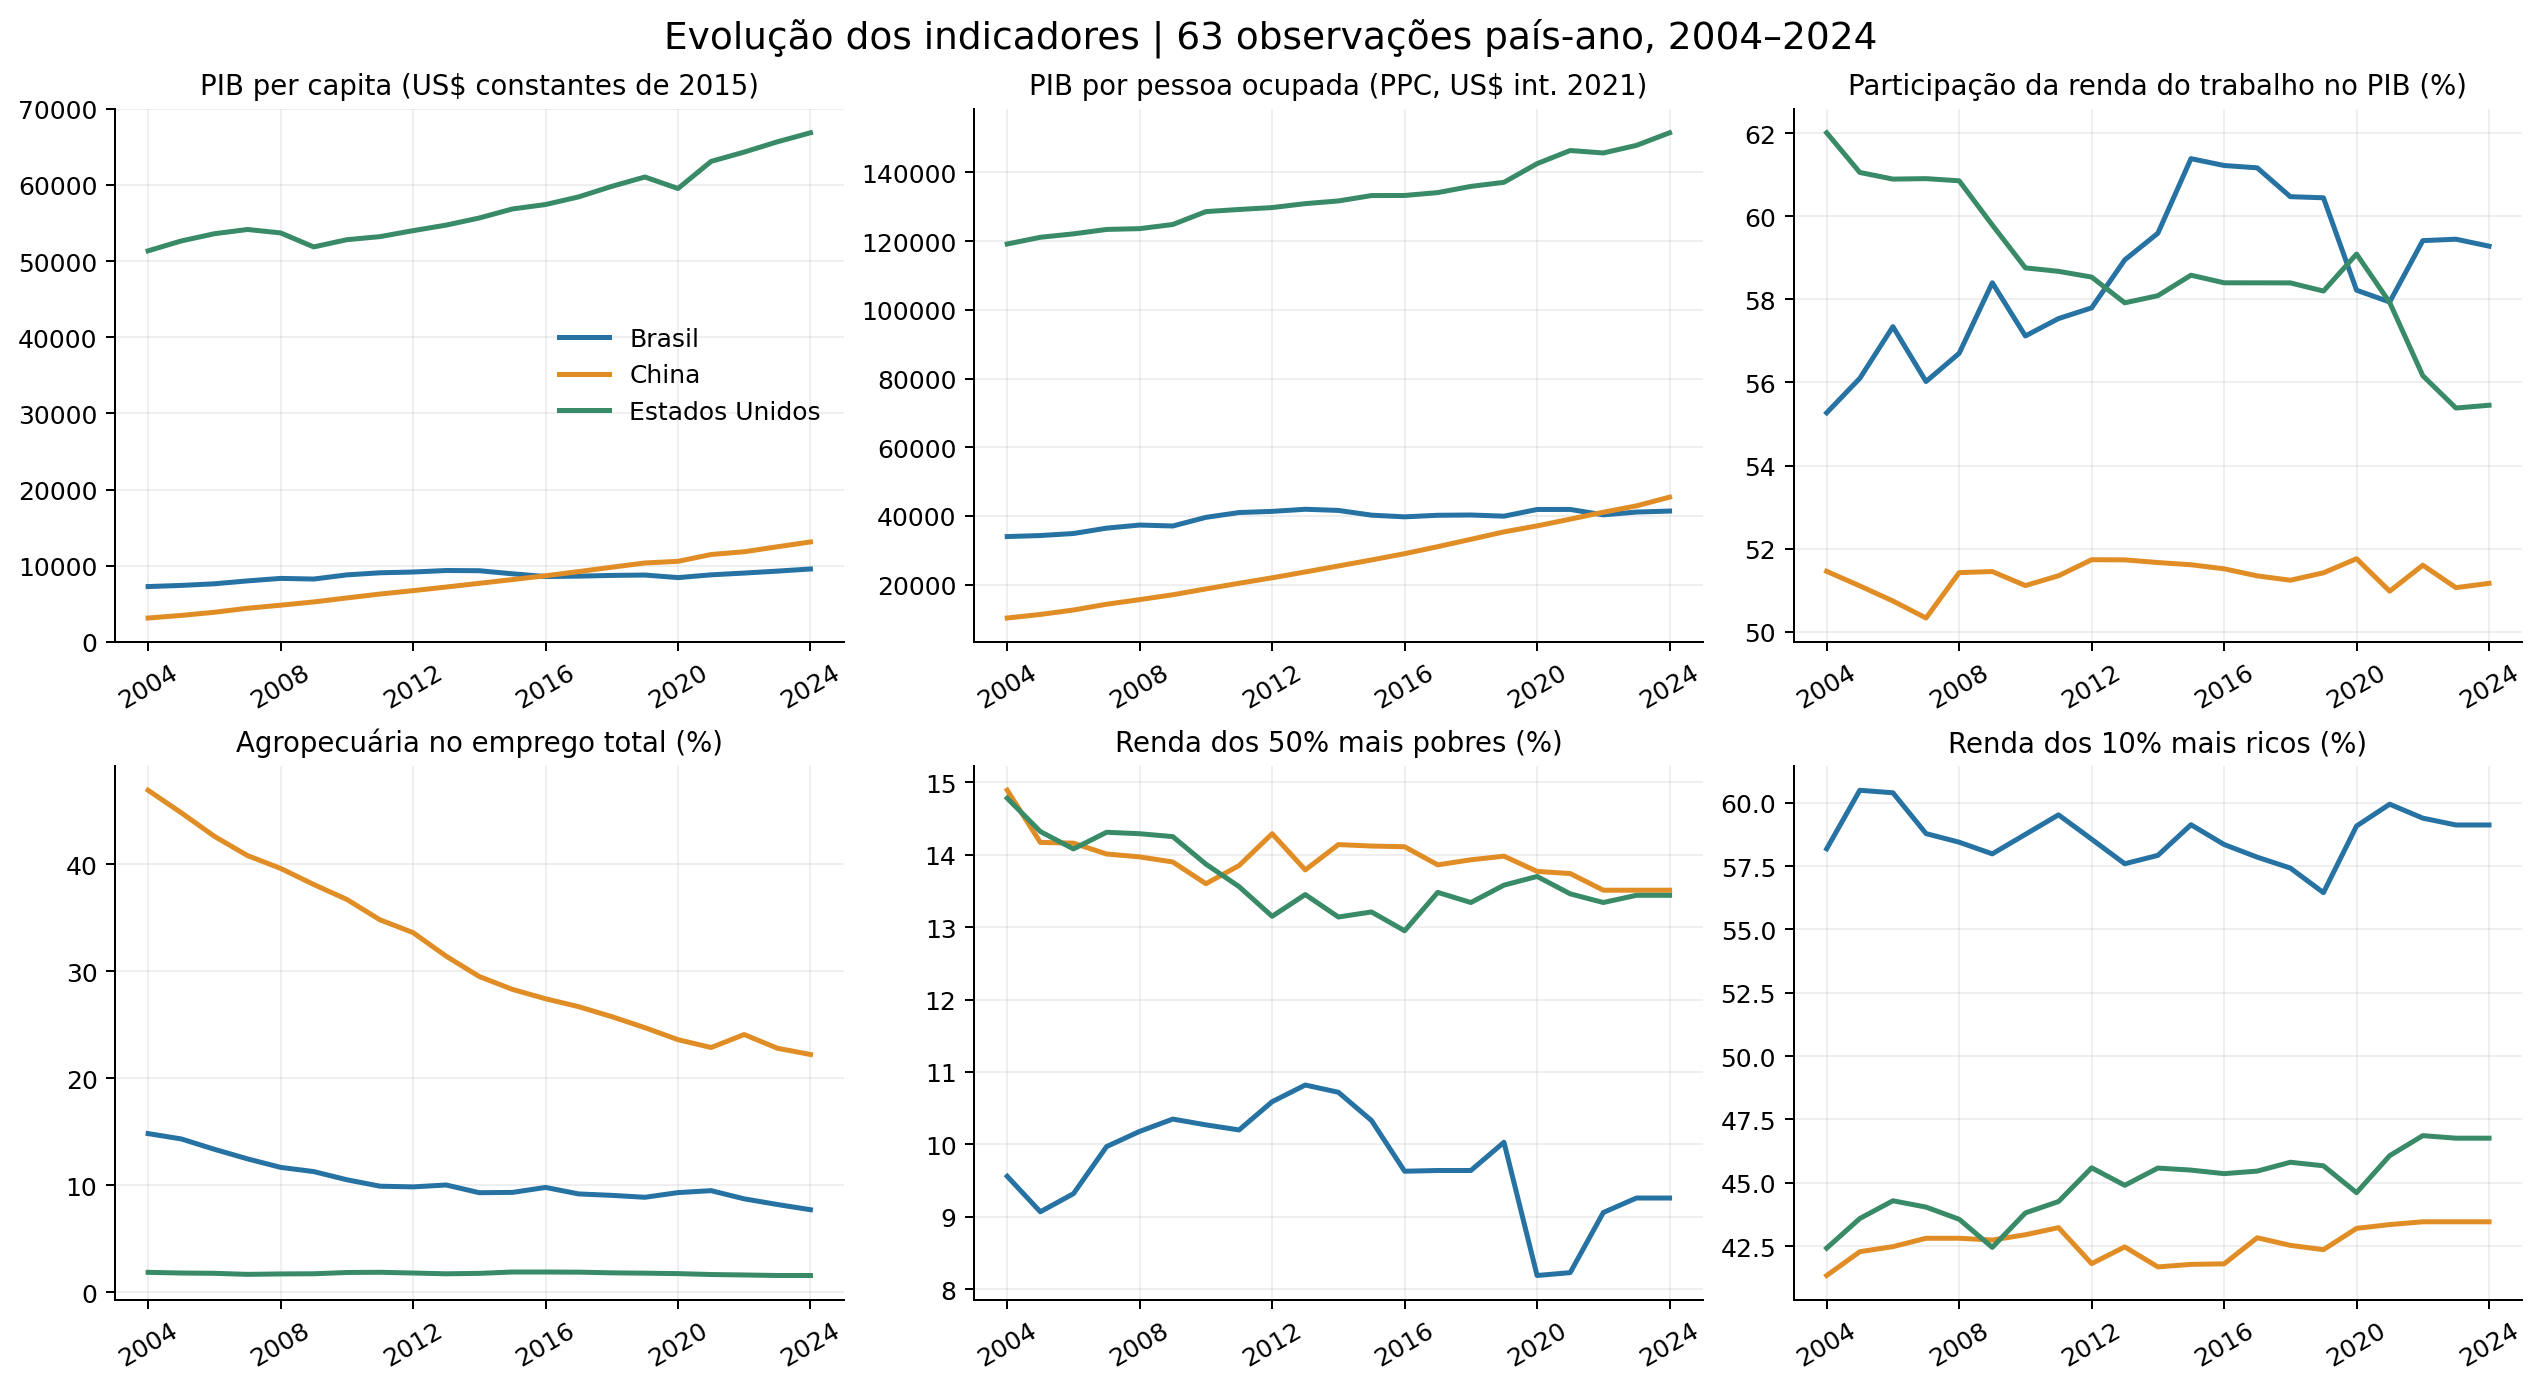

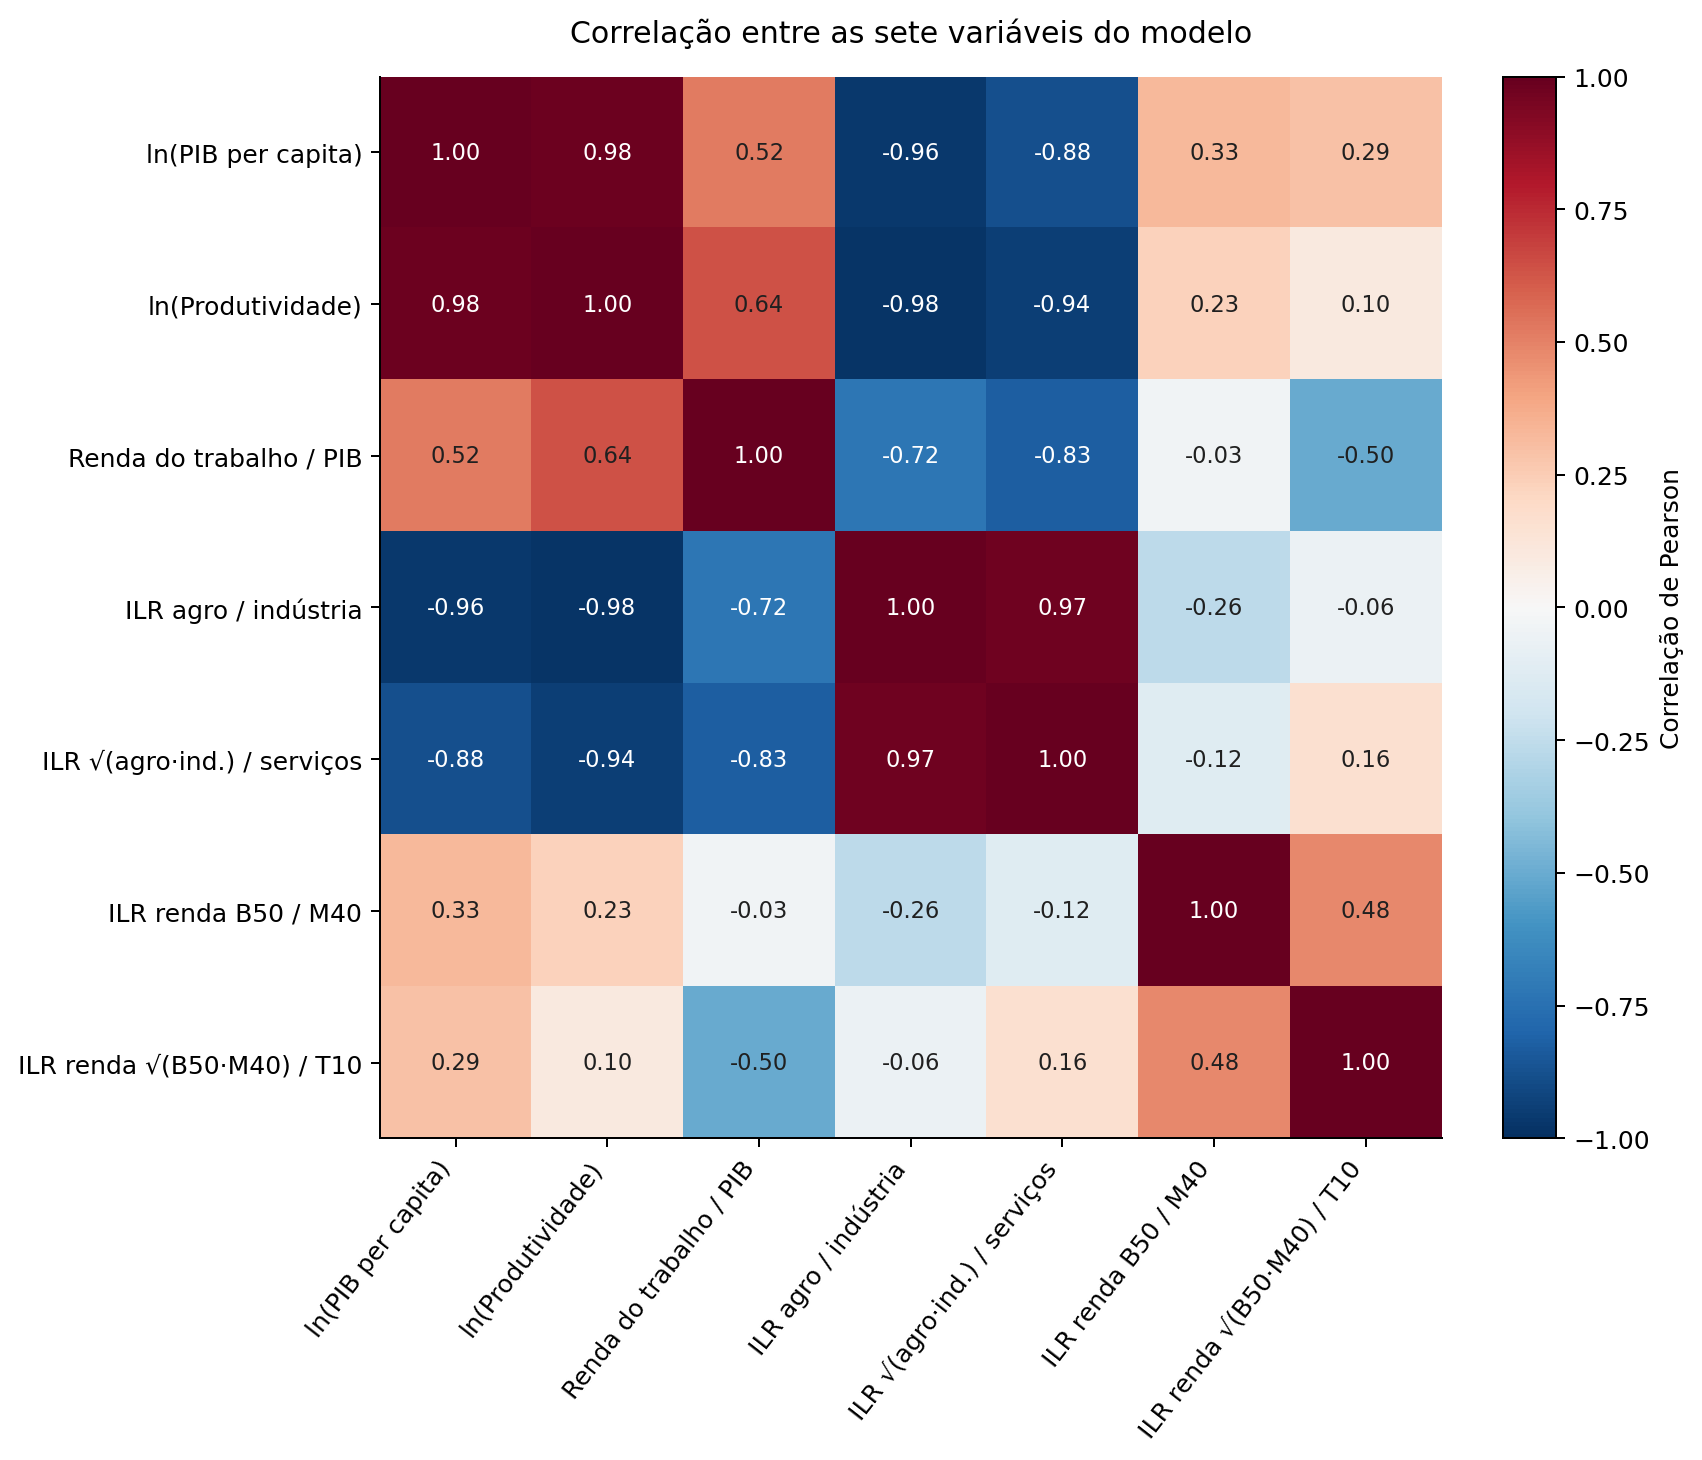

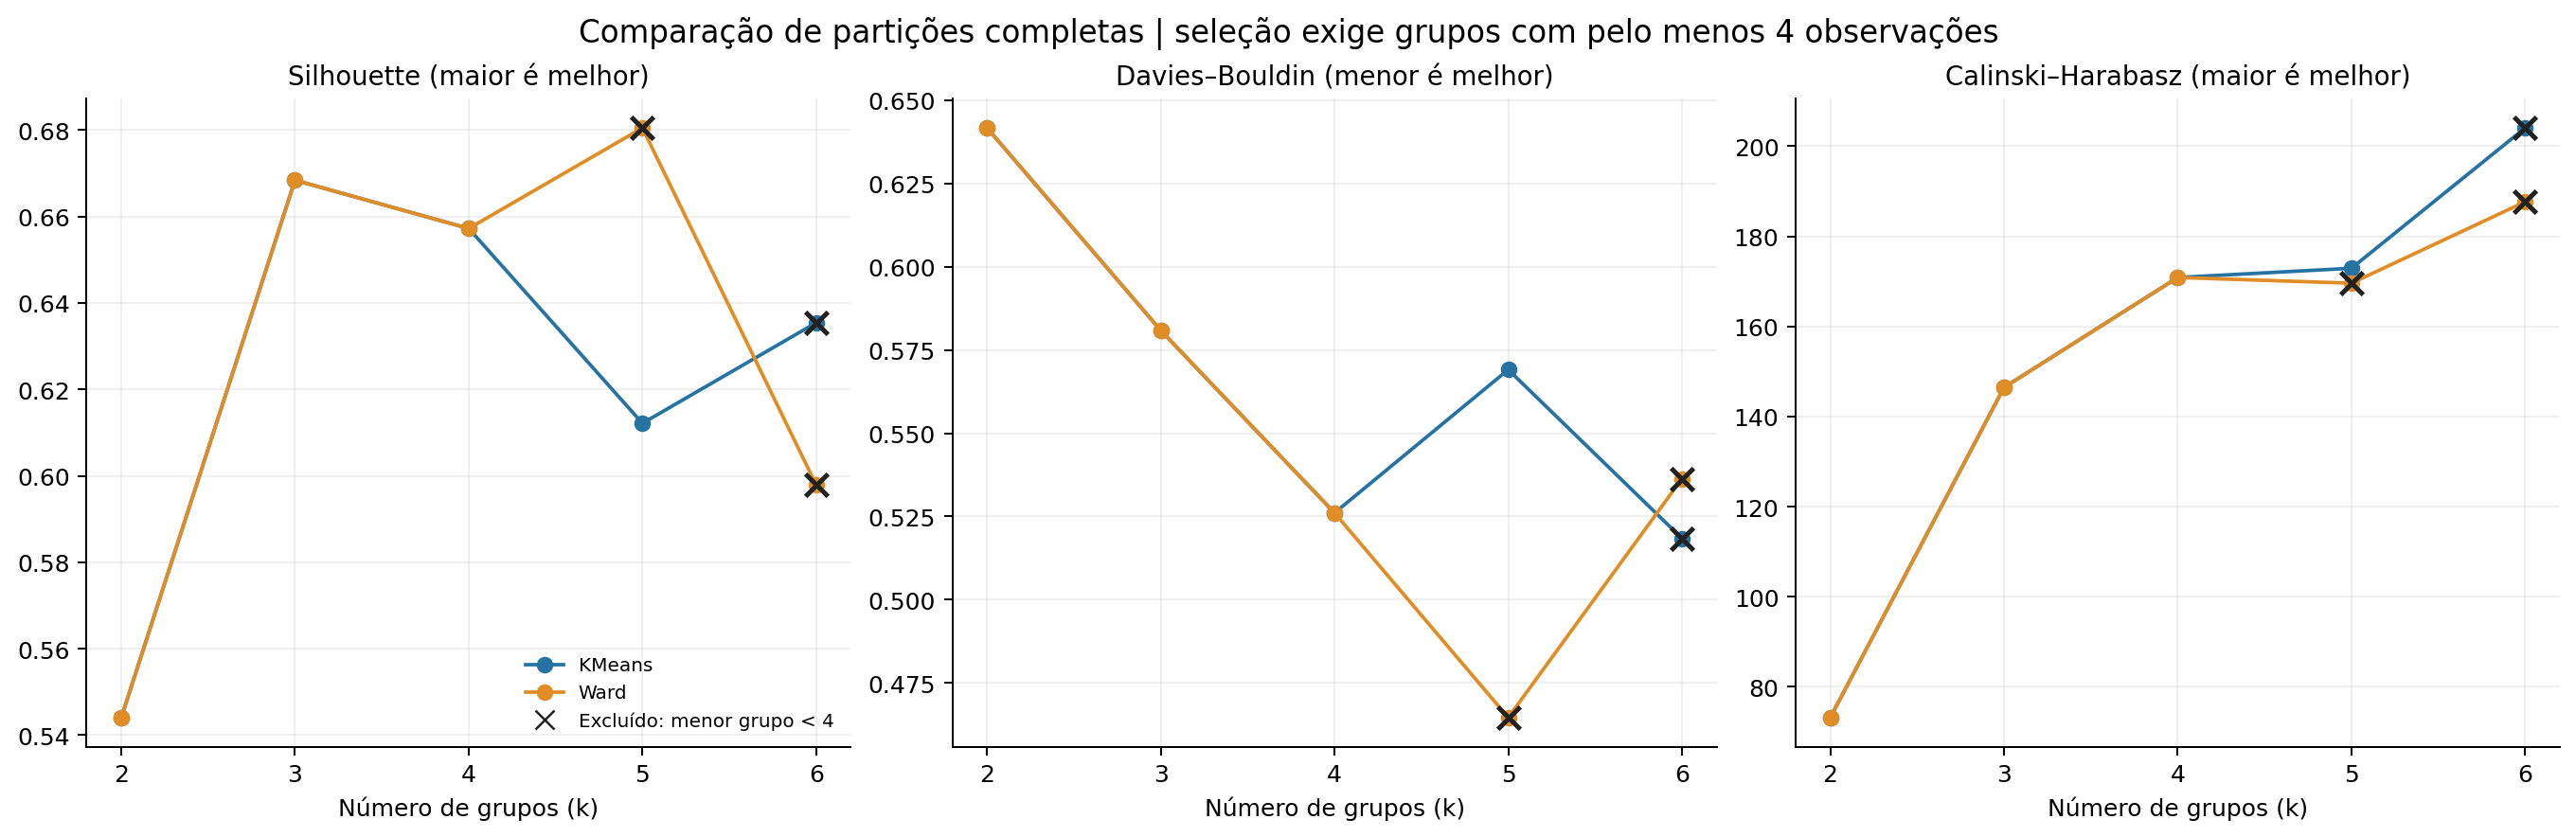

In [6]:
display(Image(filename=str(ROOT / "figures/01_eda_series.png")))
display(Image(filename=str(ROOT / "figures/02_correlacao_features.png")))
display(Image(filename=str(ROOT / "figures/03_busca_k.png")))

## 5. Interpretação dos grupos

Os rótulos são renumerados por PIB per capita mediano crescente, de 1 a K. A numeração facilita a leitura, sem representar nota de qualidade de vida. Perfis são descritos em unidades originais por medianas. Países e anos são acrescentados somente após o ajuste.

A PCA de duas componentes é exclusivamente uma visualização dos sete atributos padronizados. A parcela da variância exibida é informada; o cálculo dos grupos usa as sete dimensões, portanto distâncias na figura não equivalem integralmente às distâncias usadas pelos algoritmos.

,cluster,n_observations,countries,gdp_per_capita,productivity,labor_share,agriculture,industry,services,income_bottom50,income_middle40,income_top10
0,1,21,CHN,7686.37,25449.83,51.42,29.50,29.90,40.60,13.93,43.36,42.74
1,2,21,BRA,8771.44,40241.34,58.40,9.80,23.22,67.12,9.64,31.60,58.75
2,3,21,USA,55665.24,131689.95,58.54,1.77,19.68,78.48,13.48,41.63,45.36


cluster,1,2,3
country,,,
BRA,0,21,0
CHN,21,0,0
USA,0,0,21


,country,year,from_cluster,to_cluster


Variância explicada pela PCA em 2D: 88.99%


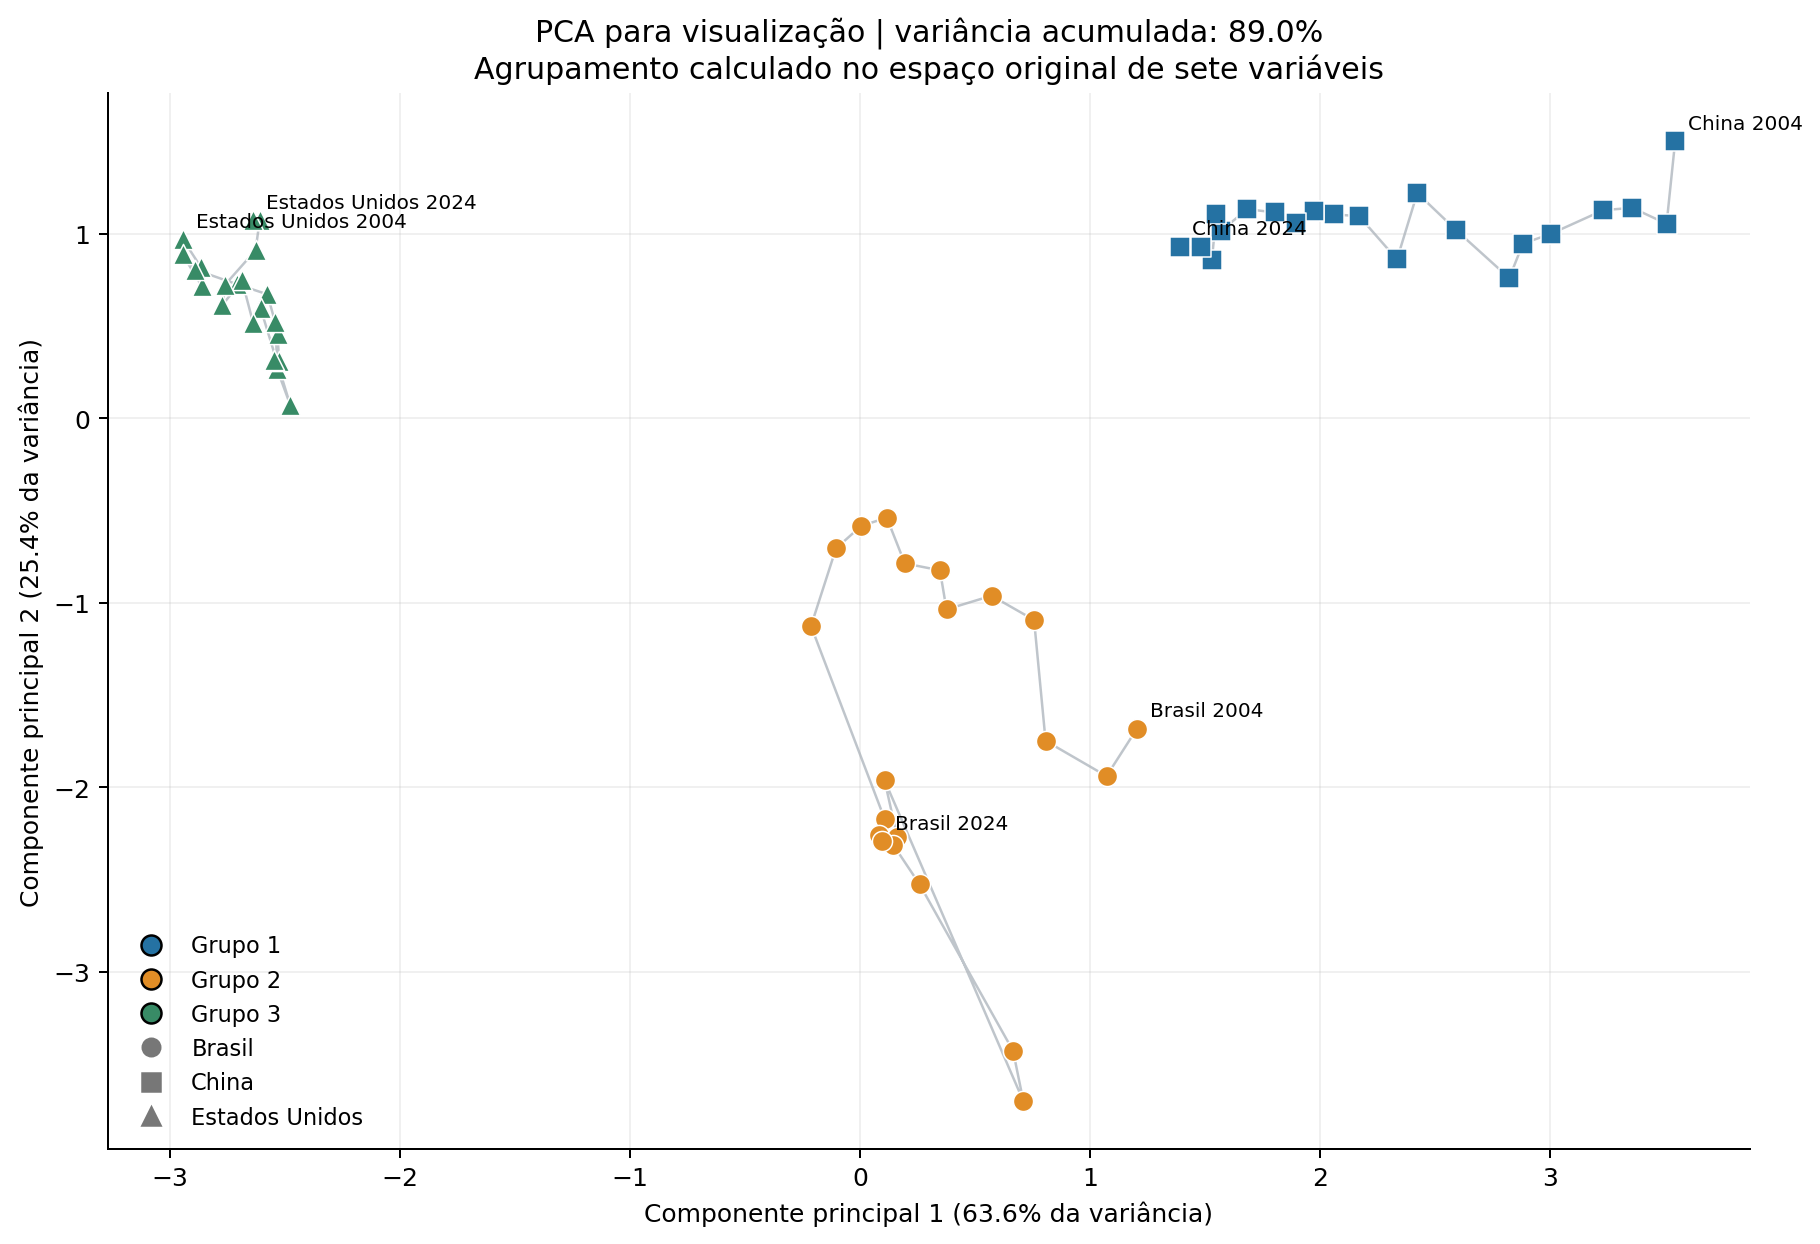

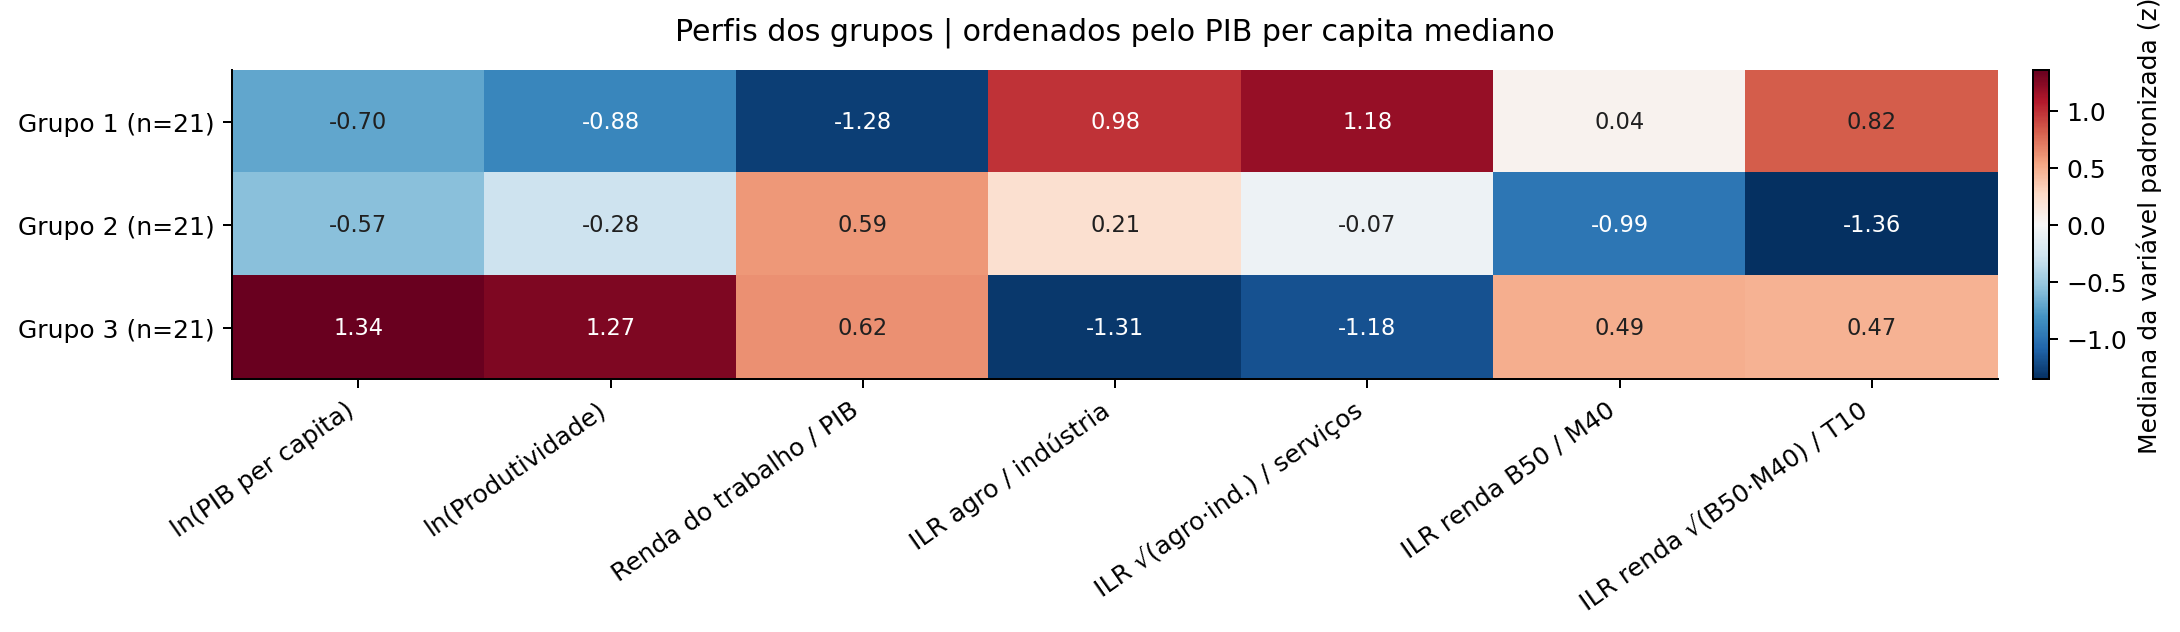

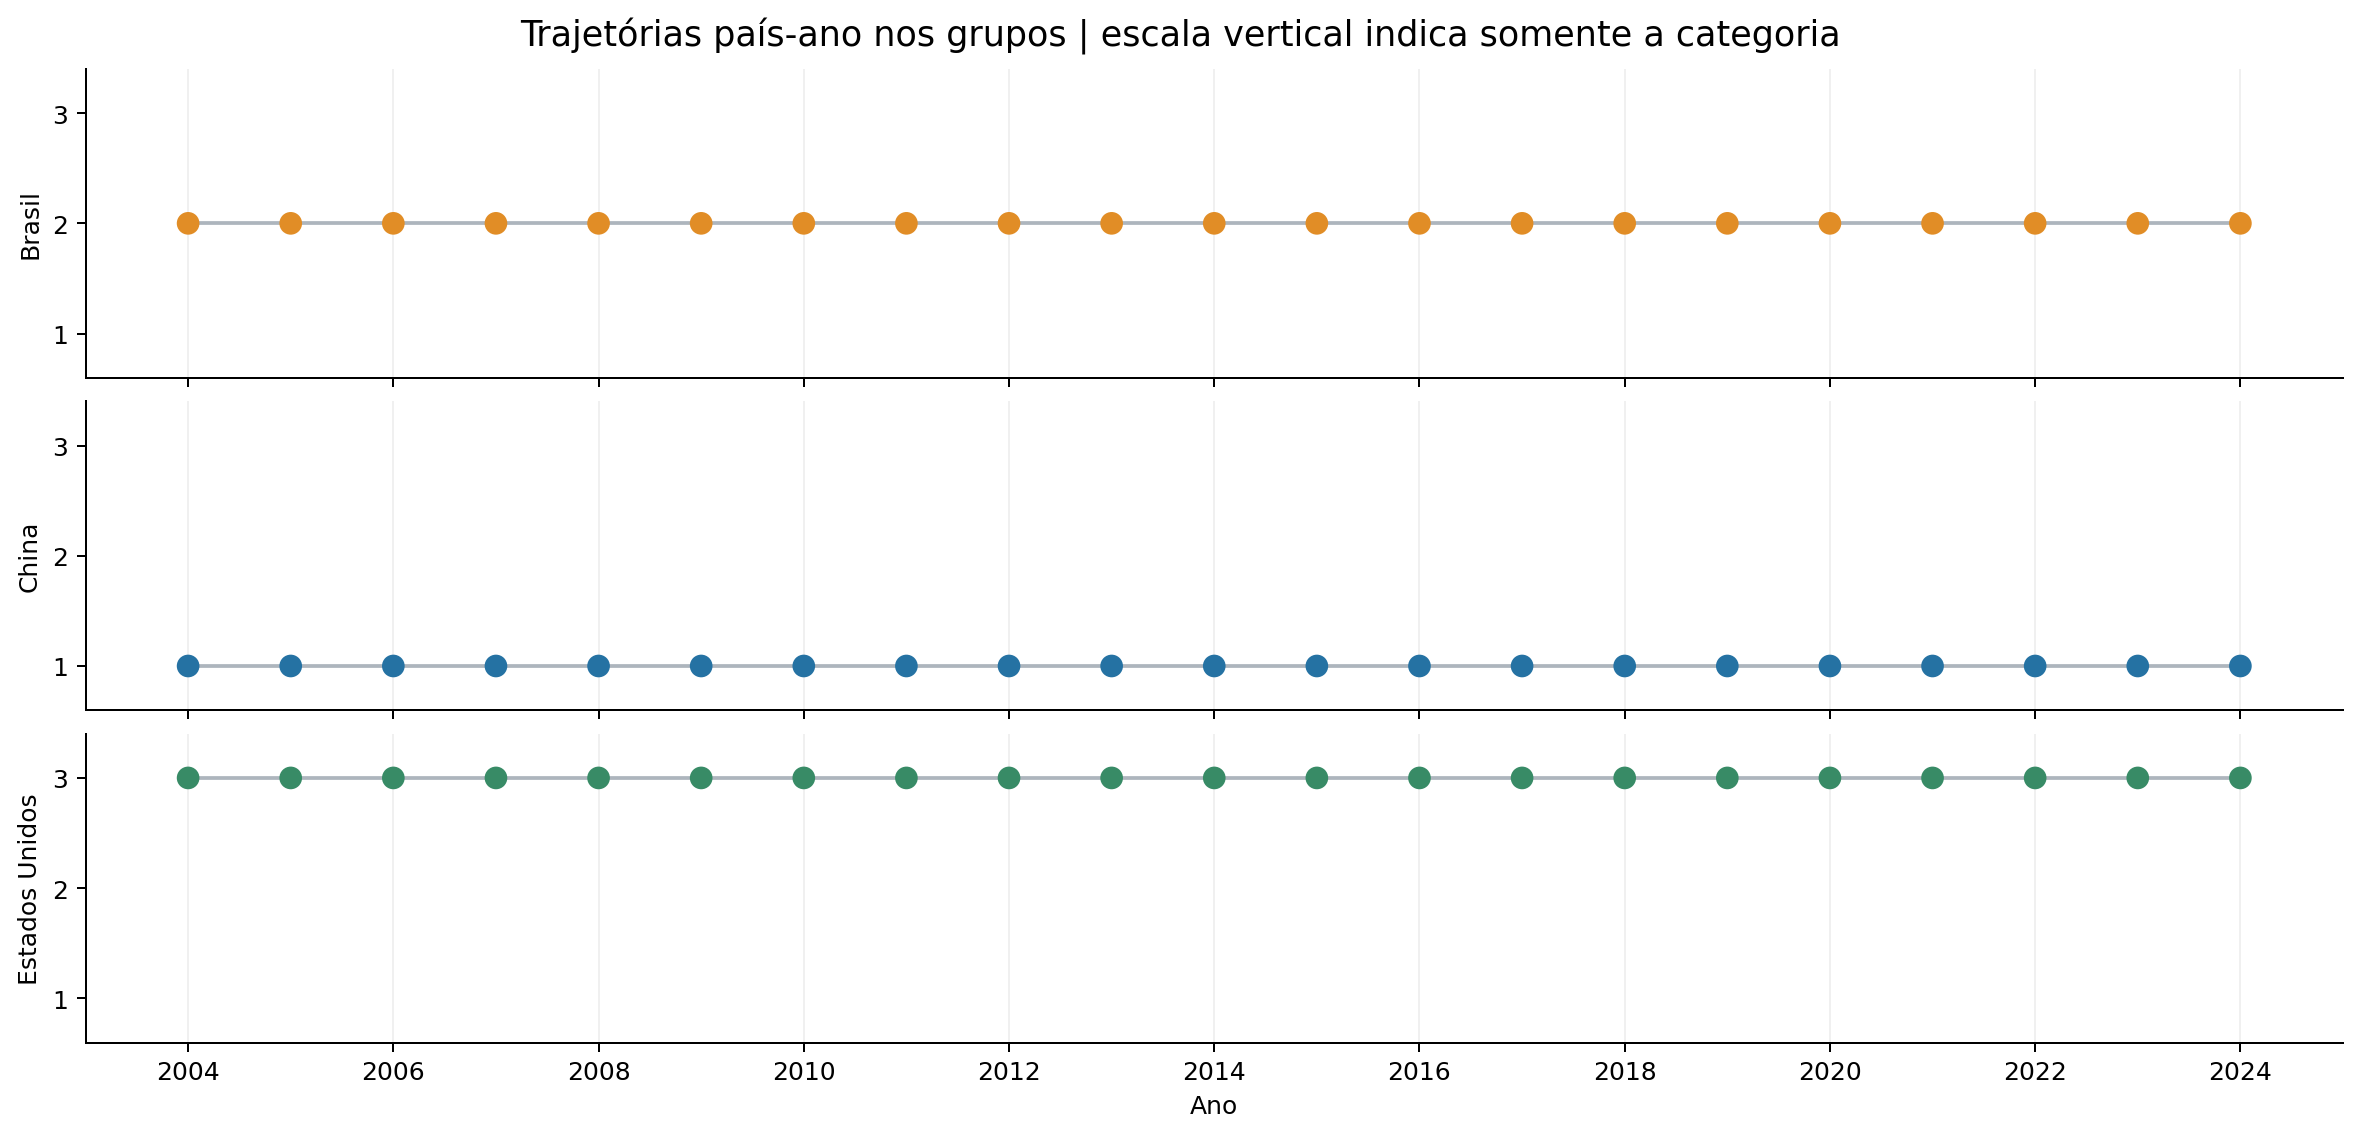

In [7]:
profiles = pd.read_csv(ROOT / "data/processed/perfis.csv")
clustered = pd.read_csv(ROOT / "data/processed/painel_clusters.csv")
display(profiles[["cluster", "n_observations", "countries", *RAW_COLUMNS]].round(2))
display(pd.crosstab(clustered.country, clustered.cluster))
display(pd.read_csv(ROOT / "results/transicoes.csv"))
print("Variância explicada pela PCA em 2D:", f'{summary["pca_total_explained_2d"]:.2%}')
display(Image(filename=str(ROOT / "figures/04_pca_clusters.png")))
display(Image(filename=str(ROOT / "figures/05_perfis_heatmap.png")))
display(Image(filename=str(ROOT / "figures/06_trajetorias_clusters.png")))

## 6. Estabilidade experimental e análise de sensibilidade

**Tempo:** retiramos cada um dos 18 blocos contíguos de quatro anos simultaneamente nos três países. Em cada caso, o tratamento e o agrupamento são reajustados nas 51 linhas restantes. O ARI compara essa partição com a partição de referência restrita às mesmas linhas. ARI igual a 1 indica concordância; não é acurácia. Os blocos se sobrepõem e não são réplicas independentes.

**Inicialização:** repetimos o melhor K-Means com 20 sementes e 50 inicializações em cada ajuste.

**Representação:** mantemos os hiperparâmetros do modelo selecionado e retiramos as coordenadas de renda, retiramos PIB/produtividade, retiramos a participação do trabalho e trocamos StandardScaler por RobustScaler. Esses testes avaliam a estabilidade da solução escolhida, sem repetir a seleção inteira. Silhouettes em espaços de atributos diferentes não formam um ranking direto.

A [nota metodológica da OIT](https://www.ilo.org/resource/news/note-ilo-modelled-estimates-and-country-rankings-or-comparisons) orienta cautela em comparações com estimativas modeladas ou imputadas. Status e metadados das fontes estão preservados. Não atribuímos precisão a códigos de qualidade sem interpretação documentada.

In [8]:
display(pd.DataFrame(summary["robustness"])[["family", "n_tests", "valid_tests", "degenerate_tests", "ari_mean", "ari_min", "ari_max", "coverage_mean"]].round(4))
print("Inicializações K-Means:", summary["seed_sensitivity"])
sensitivity = pd.read_csv(ROOT / "results/sensibilidade.csv")
display(sensitivity[["variant", "n_features", "n_clusters", "coverage", "ari_vs_selected", "silhouette"]].round(4))

,family,n_tests,valid_tests,degenerate_tests,ari_mean,ari_min,ari_max,coverage_mean
0,KMeans,18,18,0,1.0000,1.0000,1.0,1.0000
1,Ward,18,18,0,1.0000,1.0000,1.0,1.0000
2,DBSCAN,18,18,0,0.9984,0.9709,1.0,0.9989


Inicializações K-Means: {'n_seeds': 20, 'ari_min': 1.0, 'ari_mean': 1.0}


,variant,n_features,n_clusters,coverage,ari_vs_selected,silhouette
0,completo_standard,7,3,1.0,1.0000,0.6684
1,sem_composicao_renda,5,3,1.0,1.0000,0.7269
2,sem_pib_e_produtividade,5,3,1.0,1.0000,0.6624
3,sem_participacao_trabalho,6,3,1.0,1.0000,0.6611
4,completo_robust_scaler,7,3,1.0,0.6634,0.5705


## 7. Resultados, limites e conclusão

Os resultados numéricos acima são produzidos pela execução, e a discussão interpretativa completa está em `docs/relatorio.md`. A comparação não usa país como rótulo verdadeiro e não pretende prever crises ou descobrir relações causais.

Limites principais: somente três países; observações anuais dependentes; séries modeladas e sujeitas a revisões; indicadores correlacionados podem dar peso implícito maior a uma dimensão; métricas internas não provam a existência de grupos naturais. Retirar blocos avalia estabilidade descritiva, sem demonstrar generalização para outros países ou períodos. A padronização de cada coordenada ILR também define pesos relativos na geometria do modelo; por isso a representação precisa ser explicitada.

O resultado pode orientar comparações de perfis e a escolha de casos para investigação econômica posterior. Os grupos e as transições requerem interpretação contextual antes de apoiar qualquer decisão.

In [9]:
selected = summary["selected"]
display(Markdown(f'''**Síntese obtida nesta execução:** {selected["config"]},
{selected["metrics"]["n_clusters"]} grupos e silhouette de {selected["metrics"]["silhouette"]:.3f},
com cobertura de {selected["metrics"]["coverage"]:.0%}.
A referência K-Means k=2 teve silhouette de {summary["baseline"]["metrics"]["silhouette"]:.3f}.
Consulte perfis, transições e sensibilidades para interpretar essa separação.'''))
for item in summary["limitations"]:
    print("•", item)

**Síntese obtida nesta execução:** {'family': 'KMeans', 'k': 3},
3 grupos e silhouette de 0.668,
com cobertura de 100%.
A referência K-Means k=2 teve silhouette de 0.544.
Consulte perfis, transições e sensibilidades para interpretar essa separação.

• Somente três países e 21 anos: resultados descritivos do painel selecionado, sem representatividade mundial.
• Observações sucessivas de um país são dependentes; estabilidade por blocos não fornece inferência causal nem intervalos de confiança.
• Indicadores econômicos correlacionados podem aumentar implicitamente o peso de certas dimensões; análise de sensibilidade documentada.
• As métricas internas usam geometria dos próprios atributos, sem verdade externa para confirmar os grupos.
• Rótulos de grupo são categorias ordenadas pelo PIB mediano, sem interpretação de ranking de qualidade de vida.
• Não foi realizada previsão, classificação supervisionada ou avaliação de generalização fora destes países.


## 8. Referências e entrega

- Banco Mundial: [PIB per capita](https://data.worldbank.org/indicator/NY.GDP.PCAP.KD) e [emprego por setor](https://data.worldbank.org/indicator/SL.AGR.EMPL.ZS).
- OIT: [ILOSTAT](https://ilostat.ilo.org/data/) e [cautelas com comparações](https://www.ilo.org/resource/news/note-ilo-modelled-estimates-and-country-rankings-or-comparisons).
- WID: [metodologia](https://wid.world/methodology/) e [dicionário](https://wid.world/codes-dictionary/).
- scikit-learn: [agrupamento e avaliação](https://scikit-learn.org/stable/modules/clustering.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) e [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

Os dados congelados e os resultados tabulares acompanham o repositório. Para a atividade: entregar o link do repositório público e o link do vídeo, que será gravado pelo estudante. `docs/roteiro_video.md` contém um roteiro vinculado aos resultados. Nenhum vídeo é gerado automaticamente.